# Reading ESMF unstructured meshes with `pyramids-mesh`

**ESMF** (Earth System Modeling Framework) defines a NetCDF **unstructured-mesh** convention used to describe grids for regridding between Earth-system model components. The file lists node coordinates (`nodeCoords`) and an element–node connectivity table (`elementConn` with `numElementConn` nodes per element), tagged `gridType = unstructured`.

This notebook reads the canonical ESMF example grid — `ne4np4-esmf.nc`, **866 nodes / 936 elements** — into a pyramids `UgridDataset` and tours the supported operations. Coordinates are in **degrees** of longitude/latitude.

## 1. Plotting backend and a `show()` helper

Every figure in this notebook is rendered through `cleopatra`/matplotlib. So the notebook executes identically in CI and interactively, we pin the non-interactive **`Agg`** backend *before* importing `pyplot`. Agg draws into an off-screen buffer and never opens a GUI window; on its own it embeds nothing, so we add a tiny `show()` that grabs the current figure, saves it to a PNG buffer, and displays that buffer inline. Call `show()` after every plot.

In [1]:
import os
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all"); buf.seek(0); display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import pandas as pd

## 3. Locate the example file

This notebook lives in `docs/examples/`, so `examples/data/` is two levels up. The ESMF sample is `esmf/ne4np4-esmf.nc`, the canonical ESMF example mesh (classic CDF-1 NetCDF, readable by the vendored GDAL).

Paths inside a notebook are always written **relative to the notebook itself**, and pyramids' `read_file` accepts a `pathlib.Path` directly — we pass the `Path`, never `str(path)`.

In [3]:
from pathlib import Path
DATA = Path("../../examples/data")
mesh_file = DATA / "esmf" / "ne4np4-esmf.nc"
mesh_file, mesh_file.exists()

(WindowsPath('../../examples/data/esmf/ne4np4-esmf.nc'), True)

## 4. Read the mesh

`UgridDataset.read_file(path, driver="esmf")` dispatches the file to the `esmf` driver, which parses it and hands back a `UgridDataset` — the same pyramids type produced from a native UGRID NetCDF file. We name the driver explicitly here because several formats share the `.nc` suffix; `read_file` can auto-detect, but being explicit is unambiguous.

In [4]:
ds = UgridDataset.read_file(mesh_file, driver="esmf")
type(ds).__name__

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 24 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


'UgridDataset'

From here nothing in the API remembers the data came from an ESMF mesh — it is a first-class pyramids object.

## 5. Explore the dataset

A `UgridDataset` exposes summary properties describing the whole mesh: `n_node` / `n_face` (size), `crs` / `epsg` (georeferencing, if the format recorded any), `bounds` (spatial extent), and `data_variable_names` (any attached fields).

In [5]:
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "bounds": ds.bounds,
    "data_variable_names": ds.data_variable_names,
})

n_node                                                    866
n_face                                                    936
crs                                                      None
epsg                                                     None
bounds                 (0.0, -90.0, 353.78115294937453, 90.0)
data_variable_names                                        []
dtype: object

**936 quadrilateral faces** (the ESMF *elements*) on **866 nodes**. `crs`/`epsg` are `None` (ESMF records lon/lat with no CRS) and `data_variable_names` is empty — this is a grid description, not a field dataset. The `bounds` reaching `−90 → 90` in latitude flag degree coordinates.

## 6. Coordinates are in DEGREES

ESMF node coordinates are in **degrees** of longitude/latitude (not radians like MPAS/ICON). The ranges confirm it: longitude up to ≈ 354, latitude the full `−90 → 90`.

In [6]:
nx, ny = np.asarray(ds.mesh.node_x), np.asarray(ds.mesh.node_y)
pd.Series({
    "node_x min/max": (float(nx.min()), float(nx.max())),
    "node_y min/max": (float(ny.min()), float(ny.max())),
    "two_pi": float(2*np.pi), "half_pi": float(np.pi/2),
})

node_x min/max    (0.0, 353.78115294937453)
node_y min/max                (-90.0, 90.0)
two_pi                             6.283185
half_pi                            1.570796
dtype: object

`node_y` spans the full **`−90 → 90`** and `node_x` runs up near **354** — plainly degrees. No radian conversion is needed; you would only assign a geographic CRS before CRS-aware steps.

## 7. The underlying `Mesh2d` topology

`ds.mesh` is the `Mesh2d` holding the raw topology. The arrays you reach for most often are `node_x`/`node_y` (node coordinates), `face_node_connectivity.data` — the `(n_face, k)` table listing the node indices of each face — and `face_areas` (one value per face).

In [7]:
mesh = ds.mesh
conn = mesh.face_node_connectivity.data
{
    "n_node": int(mesh.node_x.shape[0]),
    "connectivity_shape": conn.shape,
    "face_areas_shape": np.asarray(mesh.face_areas).shape,
    "face_centroids_shape": np.asarray(mesh.face_centroids).shape,
}

{'n_node': 866,
 'connectivity_shape': (936, 4),
 'face_areas_shape': (936,),
 'face_centroids_shape': (2, 936)}

The connectivity shape is **`(936, 4)`**: **four** nodes per element — the ne4np4 mesh is quadrilateral. The `k = 4` (versus `3`) is again why circumcenters will not apply.

## 8. The wireframe

The simplest visualization needs no data — just draw the cell edges. `plot_outline()` renders the mesh skeleton through cleopatra; it is the fastest sanity check that a file read in correctly.

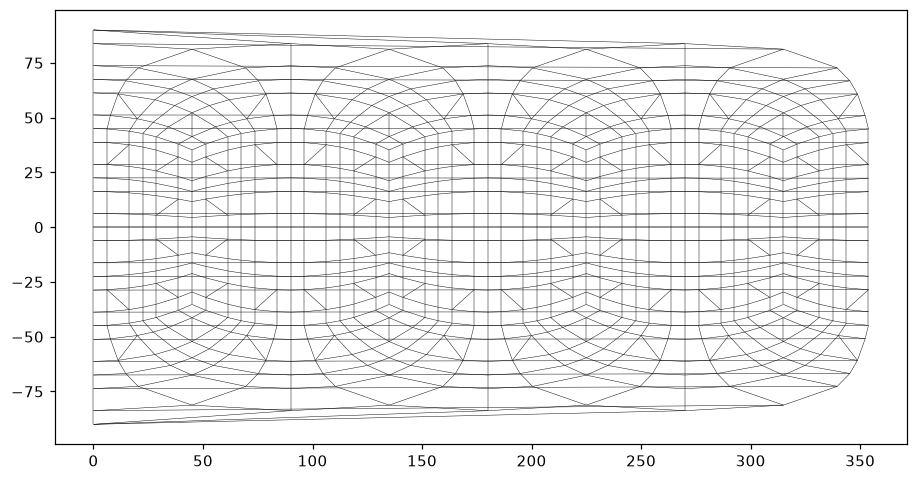

In [8]:
ds.plot_outline()
show()

The wireframe shows the ne4np4 cubed-sphere-style layout unrolled to lon/lat: quadrilateral elements that distort toward the poles under constant-degree spacing.

## 9. A data map: per-cell area

An ESMF mesh file carries no field values, so we synthesise one. We compute each cell's area from the geometry and attach it as a face-located variable with `with_variable(...)`, which returns a **new** dataset (the original `ds` is left untouched). Colouring by it produces the generic pyramids data-map that any per-cell field (depth, velocity, …) would use.

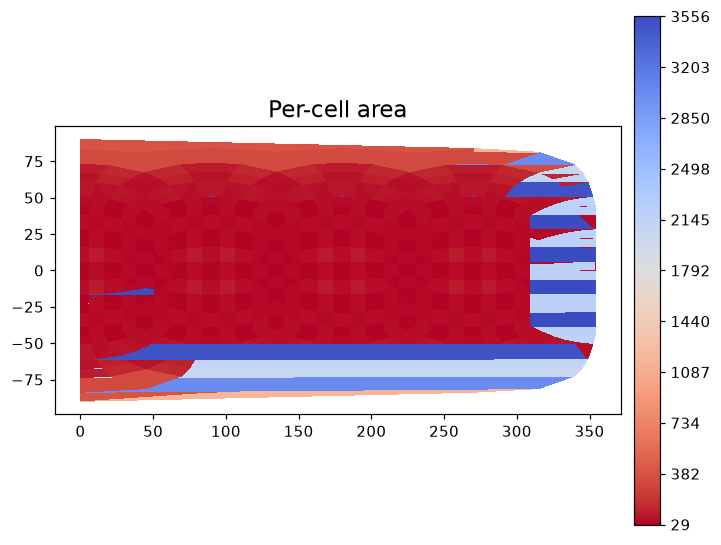

In [9]:
d2 = ds.with_variable("face_area", np.asarray(mesh.face_areas), location="face")
d2.plot("face_area", cmap="viridis", colorbar=True, title="Per-cell area")
show()

Each element is shaded by area (degree-squared units). As with every lon/lat global grid the cells appear larger near the equator and smaller toward the poles.

`summary()` reports per-variable statistics (count, min, max, mean, std) for every attached field.

In [10]:
d2.summary()

,count,min,max,mean,std
variable,,,,,
face_area,936,28.797522,3555.833297,128.004009,404.14241


The single `face_area` row (count = 936) captures the equator-to-pole size spread numerically.

## 10. GIS operations, for free

Because the mesh is a pyramids object, the pyramids GIS layer applies directly — none of these methods live in `pyramids-mesh`. We tour a few.

### Faces as a `GeoDataFrame`

`to_geodataframe()` turns every face into a polygon row of a geopandas `GeoDataFrame` — the standard vector structure for export to shapefile/GeoPackage or for spatial joins.

In [11]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((315 -35.264, 308.781 -37.938, 315 -4..."
1,"POLYGON ((321.219 -32.061, 315 -29.603, 315 -3..."
2,"POLYGON ((315 -29.603, 308.781 -32.061, 308.78..."
3,"POLYGON ((321.219 -37.938, 315 -41.35, 325.709..."
4,"POLYGON ((331.281 -35.17, 321.219 -32.061, 321..."


One row per face, each carrying its cell polygon. Plotting the `GeoDataFrame` directly with geopandas draws every face as a filled polygon — a second, vector-native view of the same mesh.

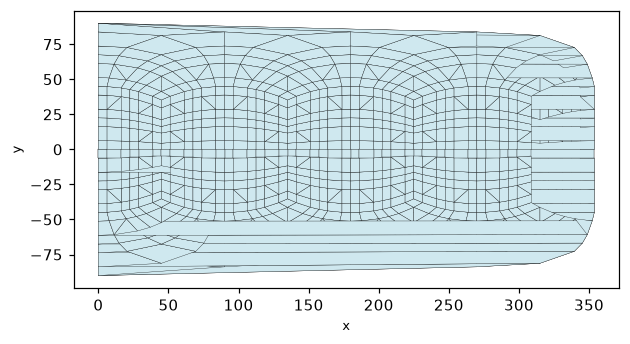

In [12]:
gdf.plot(edgecolor="black", linewidth=0.2, facecolor="#cfe8ef")
show()

One quadrilateral-element polygon per row. The CRS is unset; assign a geographic CRS before export.

### Bounding polygon

`bounding_polygon()` dissolves the elements into the mesh outline. For this global ne4np4 mesh it returns a shapely `Polygon`.

In [13]:
poly = ds.bounding_polygon()
{"type": type(poly).__name__, "bounds": ds.bounds}

{'type': 'Polygon', 'bounds': (0.0, -90.0, 353.78115294937453, 90.0)}

A single `Polygon` of the global extent — an ordinary shapely geometry for downstream clipping or export.

### Circumcenters — not applicable

`circumcenters()` is **defined only for triangular meshes**. ESMF is a **quadrilateral** mesh, so calling it raises `ValueError: circumcenters is only defined for triangular meshes.` We show the guard rather than force it — a circumcenter has no unique definition for a polygon with more than three sides.

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped:", e)

skipped: circumcenters is only defined for triangular meshes.


Expected: the operation is simply undefined for this cell shape. A triangular dual mesh would be the prerequisite for finite-volume circumcenter schemes on this grid.

### Boundary edges and face adjacency

`exterior_edges()` returns the indices of the edges that lie on the mesh boundary (each interior edge is shared by two faces; a boundary edge by one). `sparse_adjacency()` returns the face–face adjacency as a SciPy sparse matrix — the graph a flow solver walks.

In [15]:
ee = np.asarray(ds.exterior_edges())
adj = ds.sparse_adjacency()
{
    "n_boundary_edges": int(ee.shape[0]),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}

{'n_boundary_edges': 0, 'adjacency_shape': (936, 936), 'adjacency_nnz': 3600}

The `(936, 936)` adjacency matrix lists element neighbours (two non-zeros per shared edge); the boundary-edge count is the rim of the unrolled global mesh.

### Connected components

`connected_components()` labels each face by which connected piece of the adjacency graph it belongs to. The number of distinct labels tells you whether the mesh is one contiguous surface or several disjoint pieces.

In [16]:
labels = np.asarray(ds.connected_components())
n_comp = int(np.unique(labels).size)
{"n_components": n_comp, "counts": np.bincount(labels).tolist()}

{'n_components': 1, 'counts': [936]}

**One** component: the ESMF mesh is a single contiguous unstructured surface.

### Cropping to a bounding box

`crop(bbox=(xmin, ymin, xmax, ymax))` returns a new `UgridDataset` holding only the faces inside the box — the mesh equivalent of a spatial window. (`subset_by_bounds(xmin, ymin, xmax, ymax)` does the same with positional arguments.) We crop to one quadrant of the extent and plot the result.

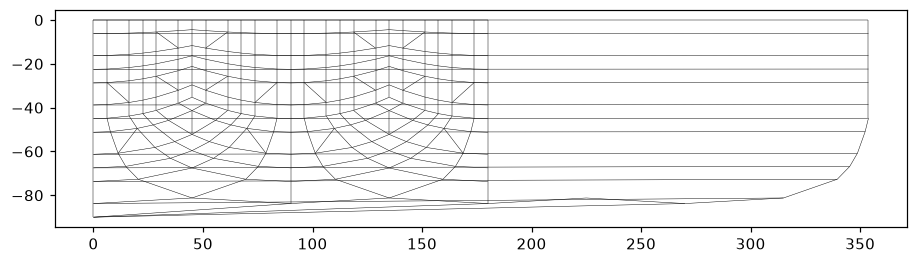

In [17]:
b = ds.bounds
bbox = (b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2)
cropped = ds.crop(bbox=bbox)
cropped.plot_outline()
show()

Cropping to one quadrant of the degree extent keeps only the elements in that lon/lat window — a contiguous block of the global mesh.

### Writing the mesh back out

`to_file(path, driver=...)` serialises the mesh through any **write-capable** driver. We round-trip to Stanford **PLY** (`driver="ply"`), which stores arbitrary polygon faces, into a temp file and read it back to confirm the topology survived.

In [18]:
import tempfile
out = Path(tempfile.gettempdir()) / "esmf_roundtrip.ply"
ds.to_file(out, driver="ply")
back = UgridDataset.read_file(out, driver="ply")
{"wrote_bytes": out.stat().st_size, "n_face_back": back.n_face, "matches": back.n_face == ds.n_face}

{'wrote_bytes': 49663, 'n_face_back': 936, 'matches': True}

The face count survives the round-trip: the mesh we read from an ESMF mesh wrote cleanly to a different format and came back identical. PLY is used because this format's own driver is read-only — `to_file` dispatches to whichever driver advertises a write capability.

### Back to `xarray`

`to_xarray()` exposes the dataset as an `xarray.Dataset` of UGRID variables — the bridge to the wider scientific-Python stack (dask, NetCDF export, CF tooling).

In [19]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.dims)

('Dataset',
 ['mesh2d_scalar', 'mesh2d_nNodes', 'mesh2d_nFaces', 'mesh2d_nMaxFaceNodes'])

A standard `xarray.Dataset`: from here the mesh can be written to NetCDF, chunked with dask, or fed to any CF-aware tool.

## 11. What we *cannot* do here, and why

Two pyramids operations are unavailable on this mesh, and the reasons are instructive:

- **`to_crs(epsg)` — skipped.** This grid carries **no CRS** (`crs` is `None` above), so pyramids refuses to reproject: `to_crs` raises *"Cannot reproject: source CRS is unknown."* You would first assign the known CRS (these global grids are geographic lon/lat on a sphere) and only then reproject.
- **`rasterize_like(...)` / `regrid(...)` — out of scope here.** Burning the mesh onto a raster grid or remapping between meshes is a genuine pyramids capability, but it needs a target raster/mesh and a resampling choice to be meaningful — a topic for a dedicated regridding tutorial, not this format tour.

## Takeaway

- The `esmf` driver reads an ESMF unstructured-mesh NetCDF into a pyramids `UgridDataset` from its `nodeCoords` + `elementConn` tables.
- ne4np4 elements are **quadrilaterals** (`k = 4`) with coordinates in **degrees** — so `circumcenters` is skipped (triangles only).
- The mesh is grid-only (no CRS, no fields); we attached a geometric `face_area` for a data map.
- The full pyramids GIS layer applies — `to_geodataframe`, `bounding_polygon`, adjacency, components, crop, PLY round-trip, `to_xarray` — while `to_crs` is skipped (no CRS recorded).